In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_classification

In [2]:
X,y=make_classification(n_samples=200,n_features=2,n_informative=1,n_redundant=0,
                       n_classes=2,n_clusters_per_class=1,random_state=41,hypercube=False,class_sep=10)

In [3]:
X

array([[ 0.46129481,  0.11056322],
       [ 0.49245852, -0.36693832],
       [ 0.18428489,  1.84676898],
       [-1.29125028,  0.00418963],
       [-1.9900335 ,  0.96772898],
       [-1.31724679, -1.09139336],
       [-1.27252874, -1.81830687],
       [-2.0957009 ,  0.37654946],
       [-1.77847655,  0.39327673],
       [ 0.22867881,  0.67795229],
       [-1.98915756, -0.89289622],
       [-2.14633183,  1.47991859],
       [ 0.27079872,  0.35699668],
       [ 0.24131273, -1.95074477],
       [ 0.72786019,  0.19072918],
       [ 0.59892582, -0.30483182],
       [-1.06679305,  1.76915945],
       [-1.79678671, -0.42450514],
       [-2.34164155, -0.2235331 ],
       [-1.78728974, -1.00806169],
       [-1.81570877,  0.81824865],
       [-0.95518193,  0.28637626],
       [ 0.22662562,  0.91057879],
       [-2.17114644, -0.97484942],
       [ 0.15566961, -1.2957083 ],
       [-0.90832387,  0.89730688],
       [-1.09821548,  0.14245455],
       [-1.18533933, -0.26370921],
       [ 0.14824607,

In [4]:
y

array([1, 1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0,
       1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 1, 1, 0, 1, 1, 1, 1, 0, 1, 0, 1, 0, 1, 0, 0, 1, 1, 0,
       1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0,
       1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1,
       1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 0, 0, 1, 1, 0,
       0, 1, 1, 1, 1, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1,
       0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0,
       0, 1, 0, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 1, 0, 1,
       1, 0])

In [5]:
X.shape

(200, 2)

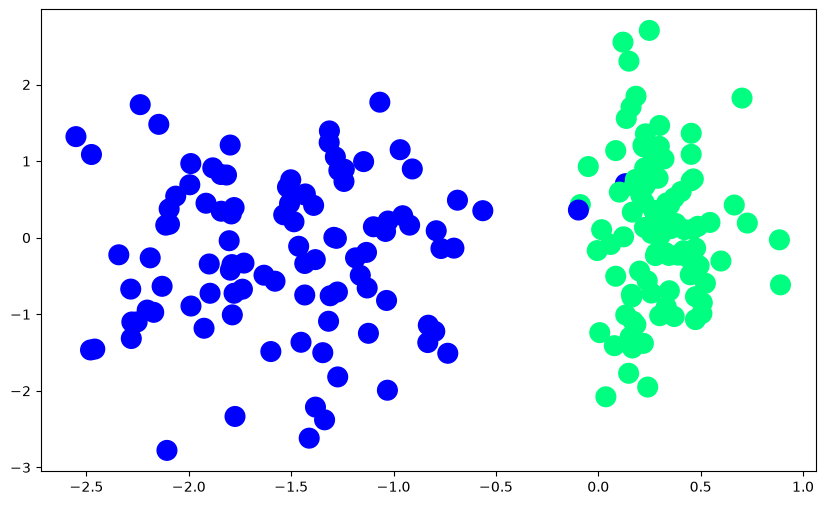

In [6]:
plt.figure(figsize=(10,6))
plt.scatter(X[:,0],X[:,1],c=y,cmap="winter",s=200)

In [7]:
def perceptron(X,y):
    X=np.insert(X,0,1,axis=1)
    weights=np.ones(X.shape[1])
    lr=0.1
    for i in range (1000):
        j=np.random.randint(0,200)
        y_hat=step(np.dot(X[j],weights))
        weights=weights+lr*(y[j]-y_hat)*X[j]
    return weights[0],weights[1:]

In [8]:
def step(z):
    return 1 if z>0 else 0

In [9]:
intercept_,coef_=perceptron(X,y)

In [10]:
print(coef_)
print(intercept_)

[1.32726441 0.0160081 ]
0.20000000000000015


In [11]:
m=-(coef_[0]/coef_[1])
b=-(intercept_/coef_[1])

In [12]:
m

np.float64(-82.91207444719598)

In [13]:
b

np.float64(-12.493678534273043)

In [14]:
x_input = np.linspace(-3,3,100)
y_input = m*x_input + b

(-3.0, 2.0)

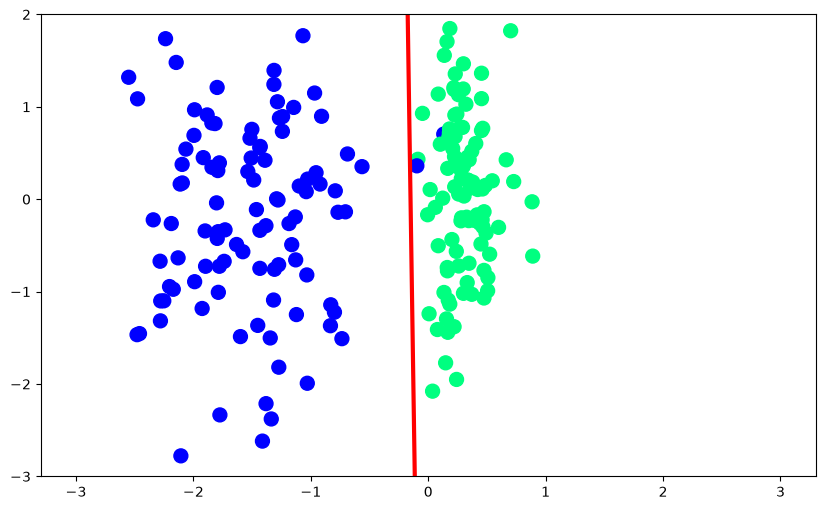

In [15]:
plt.figure(figsize=(10,6))
plt.plot(x_input,y_input,color='red',linewidth=3)
plt.scatter(X[:,0],X[:,1],c=y,cmap='winter',s=100)
plt.ylim(-3,2)

In [50]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

def Perceptron(X, y, lr=0.1, epochs=1000):
    X = np.insert(X, 0, 1, axis=1)
    weights = np.ones(X.shape[1])
    m, b = [], []
    for _ in range(epochs):
        j = np.random.randint(0, len(X))
        y_hat = int(np.dot(X[j], weights) >= 0)
        if y[j] != y_hat:
            weights += lr * (y[j] - y_hat) * X[j]
        m.append(-weights[1] / weights[2])
        b.append(-weights[0] / weights[2])

    return m, b

m, b = Perceptron(X.copy(), y)

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(X[:, 0], X[:, 1], c=y, cmap="winter", s=100)

x_i = np.linspace(X[:, 0].min() - 0.5,
                  X[:, 0].max() + 0.5, 100)

ax.set_xlim(x_i.min(), x_i.max())
ax.set_ylim(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5)

line, = ax.plot([], [], "r-", linewidth=2)
title = ax.set_title("Epoch 1")

def update(i):
    line.set_data(x_i, m[i] * x_i + b[i])
    title.set_text(f"Epoch {i + 1}")
    return line, title

anim = FuncAnimation(
    fig, update,
    frames=range(0, len(m), 5),
    interval=100, repeat=True, blit=False
)

plt.close(fig)
display(HTML(anim.to_jshtml()))